# Exploratory Data Analysis: Brazilian E-Commerce (Olist)

**Датасет:** Brazilian E-Commerce Public Dataset by Olist (Kaggle)  
**Период данных:** октябрь 2016 — октябрь 2018  
**Объём:** около 100 000 заказов, 9 таблиц  
**Инструменты:** Python, pandas, matplotlib, seaborn, scipy

---

## Цель анализа

Исследовать операционные показатели крупнейшего бразильского 
маркетплейса: динамику продаж, географию покупателей, 
популярные категории товаров и влияние скорости доставки 
на удовлетворённость клиентов.

---

## Структура анализа

1. Загрузка и объединение таблиц (merge)
2. Очистка данных
3. Анализ продаж и динамики
4. Анализ товаров и категорий
5. Анализ доставки и отзывов
6. Выводы и рекомендации

# Загрузка данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

import os

if os.path.exists('data'):
    files = os.listdir('data')
    
    print(f" Файлы в папке 'data' ({len(files)} шт.):")
    for file in files:
        print(f"  - {file}")
else:
    print(" Папка 'data' не найдена")

 Файлы в папке 'data' (9 шт.):
  - olist_customers_dataset.csv
  - olist_geolocation_dataset.csv
  - olist_orders_dataset.csv
  - olist_order_items_dataset.csv
  - olist_order_payments_dataset.csv
  - olist_order_reviews_dataset.csv
  - olist_products_dataset.csv
  - olist_sellers_dataset.csv
  - product_category_name_translation.csv


In [2]:
customers = pd.read_csv('data/olist_customers_dataset.csv')
geo = pd.read_csv('data/olist_geolocation_dataset.csv')
orders = pd.read_csv('data/olist_orders_dataset.csv')
order_items = pd.read_csv('data/olist_order_items_dataset.csv')
order_payments = pd.read_csv('data/olist_order_payments_dataset.csv')
order_reviews = pd.read_csv('data/olist_order_reviews_dataset.csv')
products = pd.read_csv('data/olist_products_dataset.csv')
sellers = pd.read_csv('data/olist_sellers_dataset.csv')
category_translation = pd.read_csv('data/product_category_name_translation.csv')

In [3]:
tables = {
    'customers': customers,
    'geo': geo,
    'orders': orders,
    'order_items': order_items,
    'order_payments': order_payments,
    'order_reviews': order_reviews,
    'products': products,
    'sellers': sellers,
    'category_translation': category_translation
}

print('размер таблиц:')
for name, df in tables.items():
    print(f"{name}: {df.shape}")



размер таблиц:
customers: (99441, 5)
geo: (1000163, 5)
orders: (99441, 8)
order_items: (112650, 7)
order_payments: (103886, 5)
order_reviews: (99224, 7)
products: (32951, 9)
sellers: (3095, 4)
category_translation: (71, 2)


# Объединение таблиц

In [4]:
customers.head(3)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


In [5]:
orders.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


In [6]:
order_items.head(3)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


In [7]:
sellers.head(3)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


In [8]:
df = pd.merge(orders, customers, on = 'customer_id')

In [9]:
df.shape

(99441, 12)

In [10]:
df = pd.merge(df, order_items, on = 'order_id')

In [11]:
df.shape

(112650, 18)

In [12]:

df = pd.merge(df, order_reviews, on = 'order_id')

In [13]:
df = pd.merge(df, products, on = 'product_id' )

In [14]:
df = pd.merge(df, sellers, on = 'seller_id' )

In [15]:
df = pd.merge(df,category_translation , on = 'product_category_name' )

In [16]:
df = pd.merge(df, order_payments, on='order_id', how='left')

## Очистка данных

In [17]:
df.dtypes

order_id                          object
customer_id                       object
order_status                      object
order_purchase_timestamp          object
order_approved_at                 object
order_delivered_carrier_date      object
order_delivered_customer_date     object
order_estimated_delivery_date     object
customer_unique_id                object
customer_zip_code_prefix           int64
customer_city                     object
customer_state                    object
order_item_id                      int64
product_id                        object
seller_id                         object
shipping_limit_date               object
price                            float64
freight_value                    float64
review_id                         object
review_score                       int64
review_comment_title              object
review_comment_message            object
review_creation_date              object
review_answer_timestamp           object
product_category

In [18]:
df.isnull().sum()

order_id                              0
customer_id                           0
order_status                          0
order_purchase_timestamp              0
order_approved_at                    14
order_delivered_carrier_date       1195
order_delivered_customer_date      2400
order_estimated_delivery_date         0
customer_unique_id                    0
customer_zip_code_prefix              0
customer_city                         0
customer_state                        0
order_item_id                         0
product_id                            0
seller_id                             0
shipping_limit_date                   0
price                                 0
freight_value                         0
review_id                             0
review_score                          0
review_comment_title             101811
review_comment_message            66703
review_creation_date                  0
review_answer_timestamp               0
product_category_name                 0


In [19]:
df[df['order_delivered_carrier_date'].isnull()]['order_status'].value_counts()

order_status
canceled       468
invoiced       358
processing     357
unavailable      7
approved         3
delivered        2
Name: count, dtype: int64

### Пустые значения сorder_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date связаны со статусом заказов и не нуждаются в заполнении

In [20]:
df = df.dropna(subset = ['product_weight_g', 'product_length_cm', 'product_width_cm'])

In [21]:
df = df.copy()

In [22]:
df['order_approved_at'] = pd.to_datetime(df['order_approved_at'])
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'])
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'])
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'])

In [23]:
df.dtypes

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp                 object
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
customer_unique_id                       object
customer_zip_code_prefix                  int64
customer_city                            object
customer_state                           object
order_item_id                             int64
product_id                               object
seller_id                                object
shipping_limit_date                      object
price                                   float64
freight_value                           float64
review_id                                object
review_score                              int64
review_comment_title                    

In [24]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

## Анализ продаж

Text(0, 0.5, 'обьем заказов')

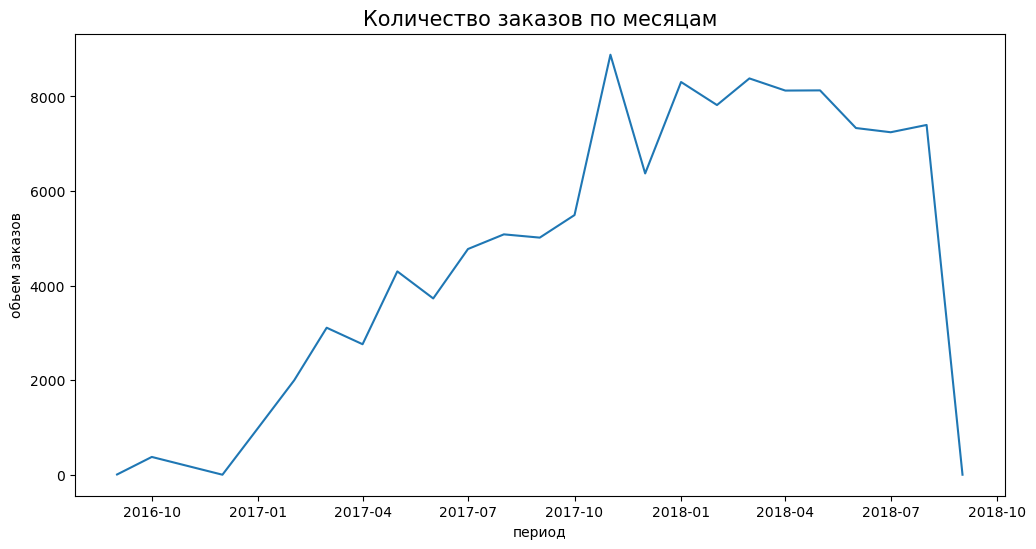

In [25]:
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

monthly_orders = df.groupby('year_month').size().reset_index(name='orders_count')
monthly_orders['date'] = monthly_orders['year_month'].dt.to_timestamp()

plt.figure(figsize =(12,6))
sns.lineplot(data = monthly_orders, x = 'date', y = 'orders_count')

plt.title('Количество заказов по месяцам', fontsize = 15)
plt.xlabel('период')
plt.ylabel('обьем заказов')


# Вывод
**С октября 2016 по ноябрь 2017 платформа показала значительный рост
количество заказов увеличилось с 200 до 8 000 в месяц.
Пик пришёлся на ноябрь 2017, предположительно в период распродаж. Резкий спад в октябре 2018 связан с
неполнотой данных, а не реальным падением продаж.**

Text(0, 0.5, 'Количество заказов')

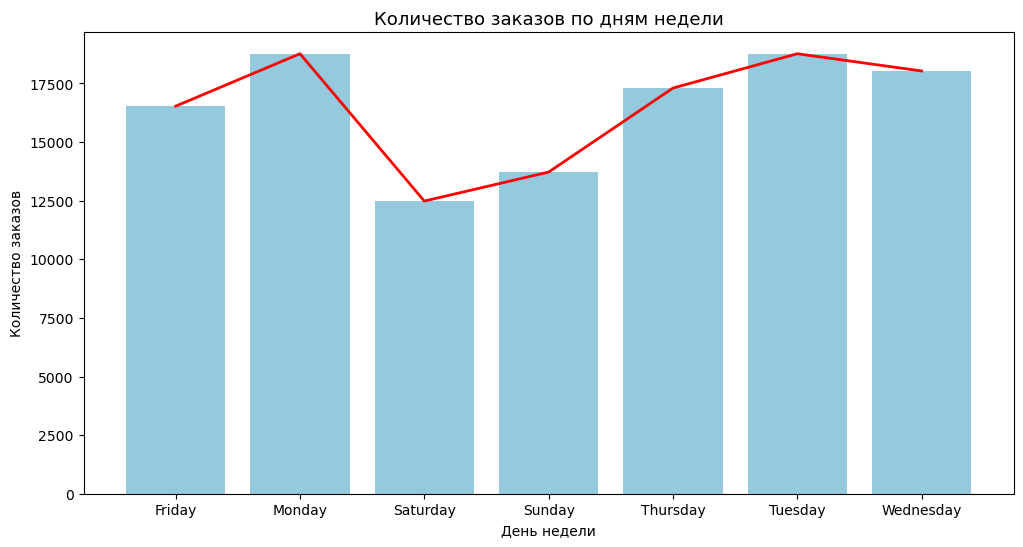

In [26]:
df['weekday'] = df['order_purchase_timestamp'].dt.day_name()

daily_orders = df.groupby('weekday').size().reset_index(name = 'daily_count')
plt.figure(figsize = (12,6))
sns.barplot(data = daily_orders, x = 'weekday', y = 'daily_count', color='skyblue')
sns.lineplot(data = daily_orders, x = 'weekday', y = 'daily_count', color='red', linewidth=2, markersize=8)

plt.title('Количество заказов по дням недели',fontsize = 13)
plt.xlabel('День недели', fontsize = 10)
plt.ylabel('Количество заказов', fontsize = 10)

# Вывод 
**Пик заказов приходится на будние дни (понедельник–вторник),
в выходные активность снижается.**

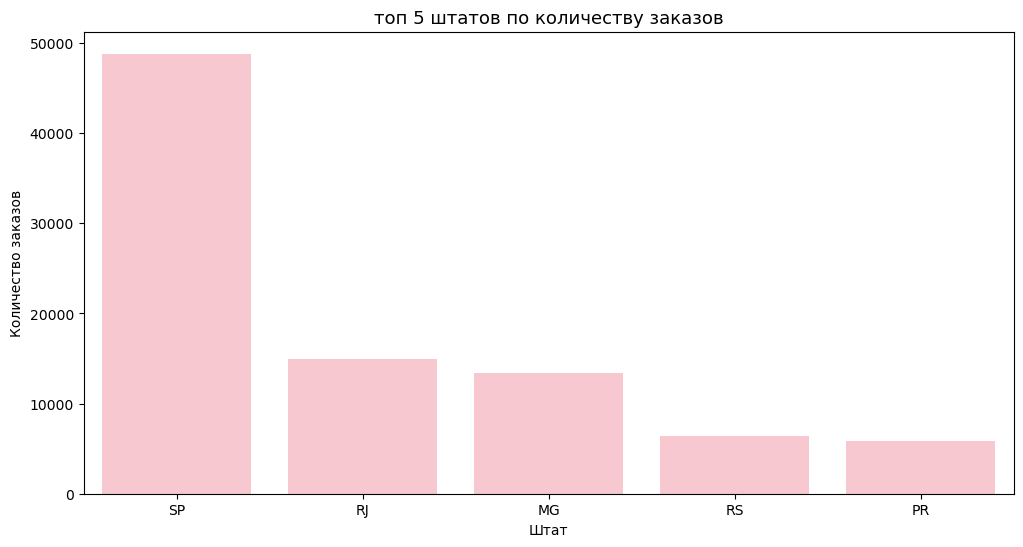

In [27]:
state = df.groupby('customer_state')['order_id'].size().sort_values(ascending = False).head(5).reset_index(name = 'state_count')

plt.figure(figsize = (12,6))
sns.barplot(data = state, x = 'customer_state', y = 'state_count' , color = 'pink')


plt.title('топ 5 штатов по количеству заказов',fontsize = 13)
plt.xlabel('Штат', fontsize = 10)
plt.ylabel('Количество заказов', fontsize = 10)
plt.show()

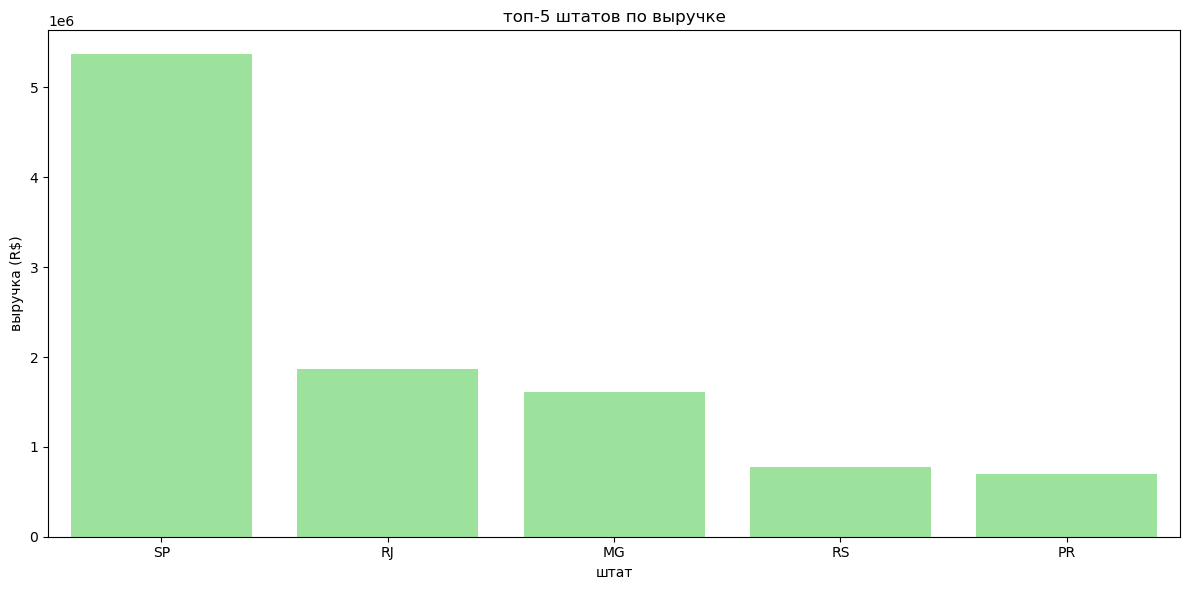

In [28]:
revenue = df.groupby('customer_state')['price'].sum().sort_values(ascending = False).head(5).reset_index(name = 'state_revenue')
plt.figure(figsize = (12,6))
sns.barplot(data = revenue, x = 'customer_state', y = 'state_revenue' , color = 'lightgreen')
plt.title('топ-5 штатов по выручке')
plt.xlabel('штат')
plt.ylabel('выручка (R$)')
plt.tight_layout()
plt.show()

# Вывод
**Штат Сан-Паулу  доминирует как по количеству заказов,
так и по выручке это соответствует его доле в экономике Бразилии.
Топ-3 штата (SP, RJ, MG) формируют основную часть продаж платформы.**

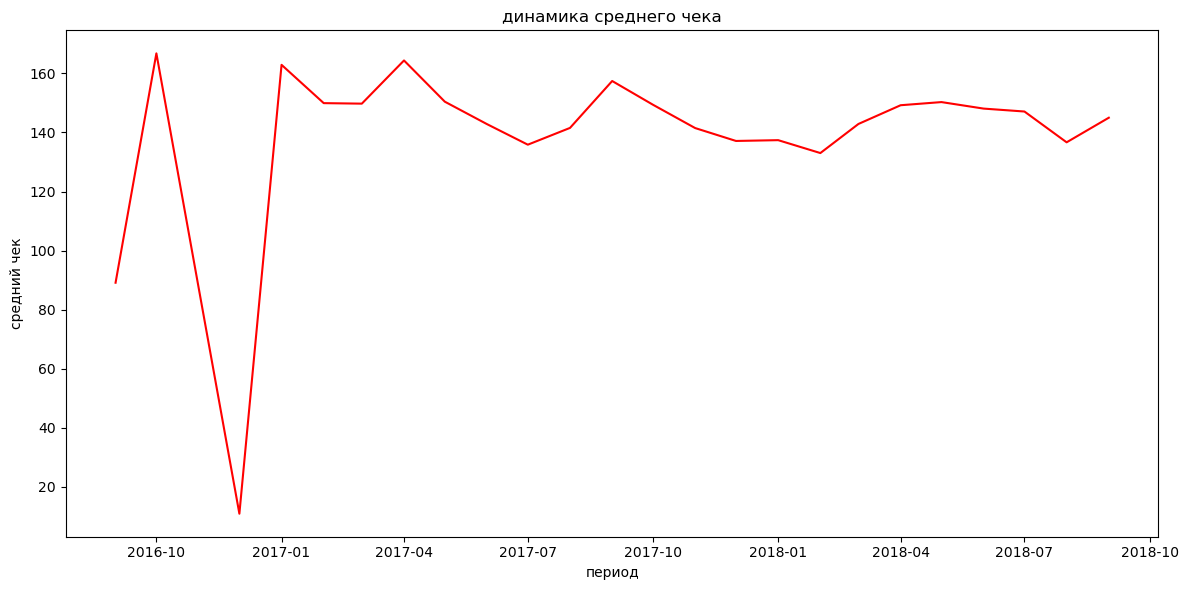

In [29]:
AOV = (df.groupby('year_month')['price'].sum()/df.groupby('year_month')['order_id'].nunique()).reset_index(name='AOV_period')

AOV['date'] = AOV['year_month'].dt.to_timestamp()
plt.figure(figsize = (12,6))
sns.lineplot(data = AOV, x = 'date', y = 'AOV_period', color = 'red')

plt.title('динамика среднего чека')
plt.xlabel('период')
plt.ylabel('средний чек')
plt.tight_layout()
plt.show()

# Вывод
**Средний чек остаётся стабильным на уровне 120-140 R$ на протяжении
всего периода. Незначительные колебания не показывают выраженного
тренда, то есть платформа не смещается ни в премиум, ни в бюджетный сегмент.**


## Анализ товаров и цен

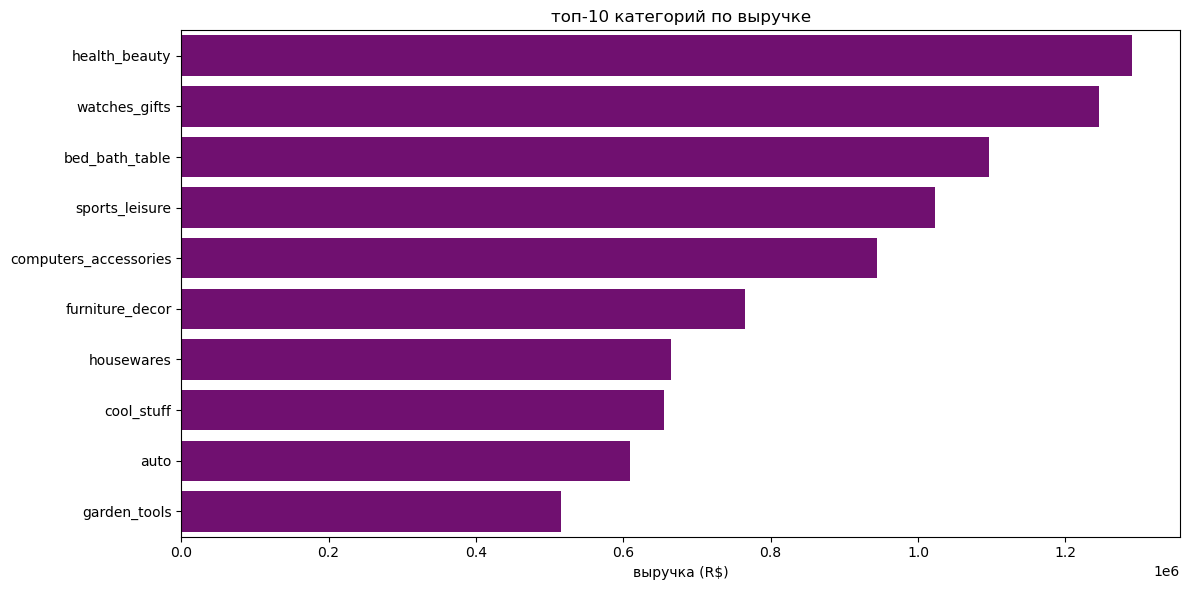

In [30]:
top_10_categories = df.groupby('product_category_name_english')['price'].sum().nlargest(10).reset_index(name = 'total_revenue')


plt.figure(figsize = (12,6))
sns.barplot(data = top_10_categories, x = 'total_revenue', y =  'product_category_name_english', color = 'purple')

plt.title('топ-10 категорий по выручке')
plt.xlabel('выручка (R$)')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [31]:
top_10_orders_count = df.groupby('product_category_name_english')['order_id'].size().nlargest(10)
top_10_orders_count

product_category_name_english
bed_bath_table           11847
health_beauty             9947
sports_leisure            8942
furniture_decor           8743
computers_accessories     8105
housewares                7331
watches_gifts             6161
telephony                 4692
garden_tools              4558
auto                      4356
Name: order_id, dtype: int64

# Вывод
**Топ категорий по выручке: bed_bath_table, health_beauty, 
computers_accessories. Интересно что высокомаржинальные категории
(электроника) дают высокую выручку при меньшем количестве заказов,
а товары для дома лидируют и по штукам, и по деньгам.**

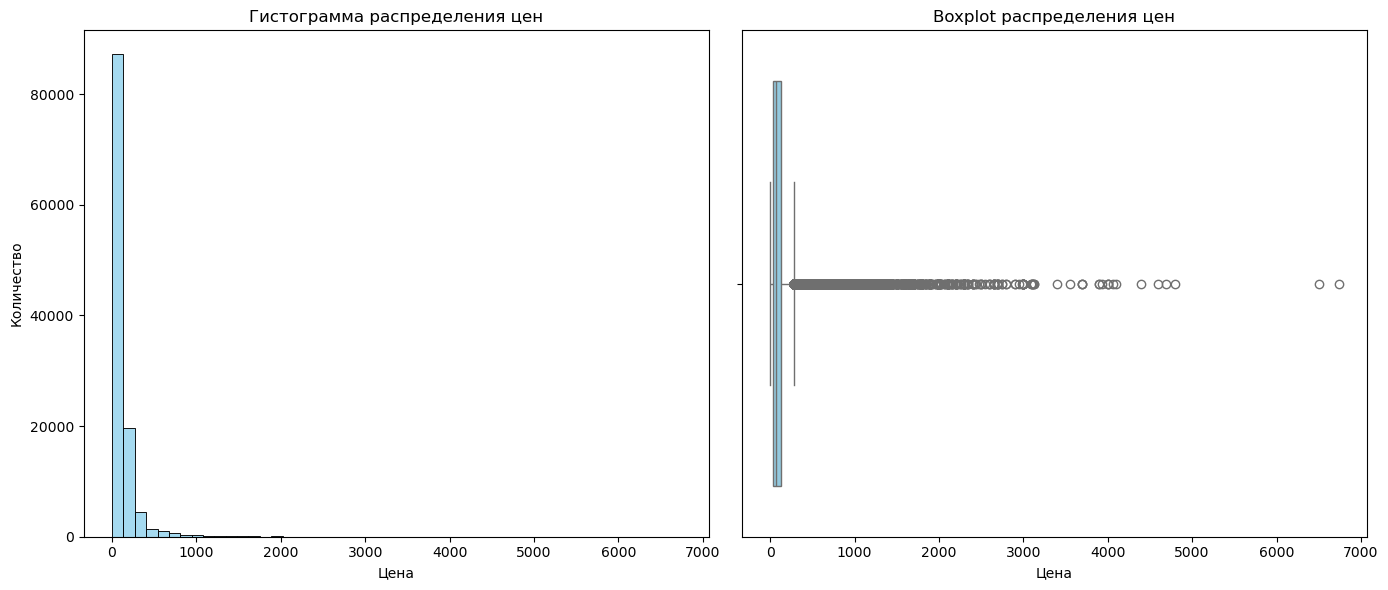

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))


sns.histplot(data=df, x='price', bins=50, ax=axes[0], color='skyblue')
axes[0].set_title('Гистограмма распределения цен', fontsize=12)
axes[0].set_xlabel('Цена')
axes[0].set_ylabel('Количество')


sns.boxplot(data=df, x='price', ax=axes[1], color='skyblue')
axes[1].set_title('Boxplot распределения цен', fontsize=12)
axes[1].set_xlabel('Цена')

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Вес товара (г)')

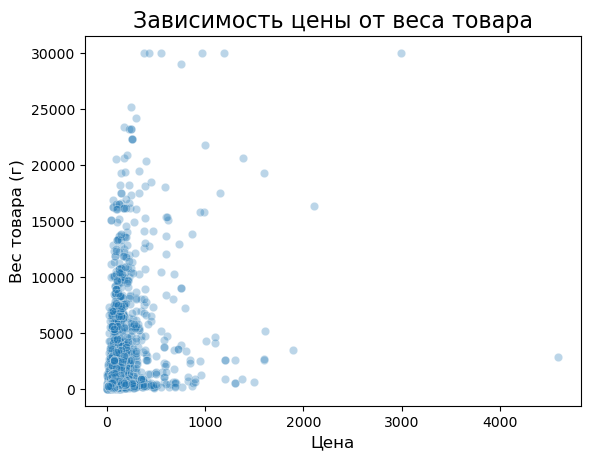

In [33]:
sns.scatterplot(data=df.sample(3000), x='price', y='product_weight_g', alpha=0.3)
plt.title('Зависимость цены от веса товара', fontsize=16 )
plt.xlabel('Цена', fontsize=12)
plt.ylabel('Вес товара (г)', fontsize=12)

## Анализ работы доставки и отзывов

Text(0.5, 0, 'Дни')

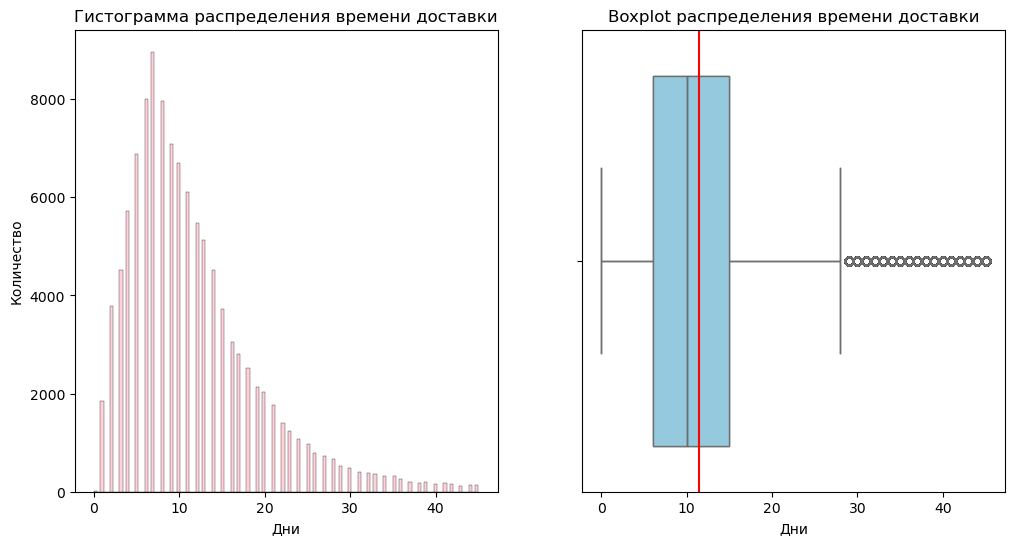

In [34]:
df['delivery_time'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.days 
df_clean = df[df['delivery_time'] >= 0]
limit = df_clean['delivery_time'].quantile(0.99)
df_clean = df_clean[df_clean['delivery_time'] <= limit]

fig, axes = plt.subplots(1,2, figsize = (12,6))

sns.histplot(data = df_clean, x = 'delivery_time', ax=axes[0], alpha = 0.7,color = 'pink')
axes[0].set_title('Гистограмма распределения времени доставки', fontsize=12)
axes[0].set_xlabel('Дни')
axes[0].set_ylabel('Количество')

sns.boxplot(data = df_clean, x = 'delivery_time')

sns.boxplot(data=df_clean, x='delivery_time', ax=axes[1],color='skyblue')
axes[1].axvline(df_clean['delivery_time'].mean(), color = 'red')
axes[1].set_title('Boxplot распределения времени доставки', fontsize=12)
axes[1].set_xlabel('Дни')

C:\Users\anast\AppData\Local\Temp\ipykernel_7880\460610988.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_score = df_clean.groupby('delivery_group')['review_score'].mean().reset_index()


Text(0, 0.5, 'Время доставки')

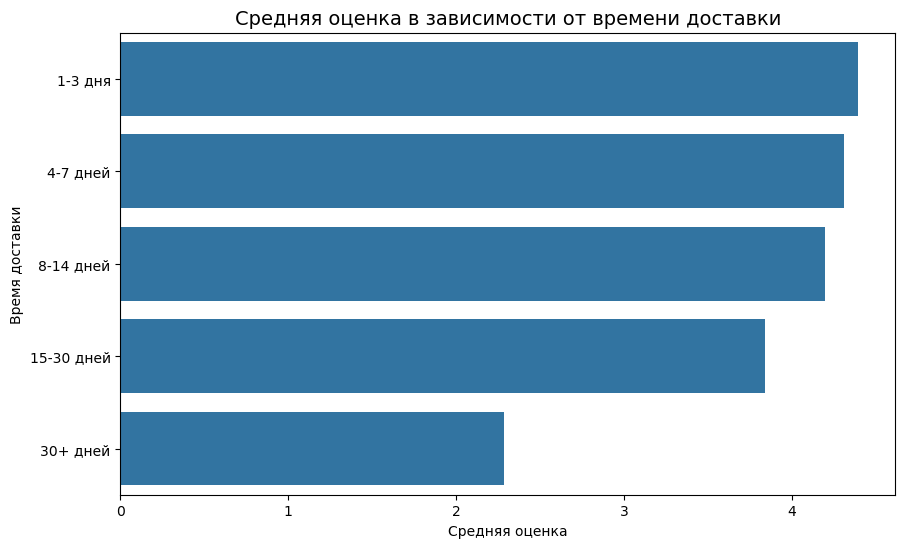

In [35]:
bins = [0, 3, 7, 14, 30, 100]  
labels = ['1-3 дня', '4-7 дней', '8-14 дней', '15-30 дней', '30+ дней']

df_clean['delivery_group'] = pd.cut(
    df_clean['delivery_time'], 
    bins=bins, 
    labels=labels, 
    right=True 
)

mean_score = df_clean.groupby('delivery_group')['review_score'].mean().reset_index()
plt.figure(figsize=(10, 6))
sns.barplot(data = mean_score, x = 'review_score', y = 'delivery_group')

plt.title('Средняя оценка в зависимости от времени доставки', fontsize=14)
plt.xlabel('Средняя оценка')
plt.ylabel('Время доставки')

# Вывод
**Чёткая обратная зависимость: при доставке 1-3 дня средняя оценка
4.4, при 30 днях падает до 2.8. Скорость доставки это главный
фактор удовлетворённости покупателей на платформе.**

[np.float64(2.255034482758621), np.float64(4.207491435528166)]


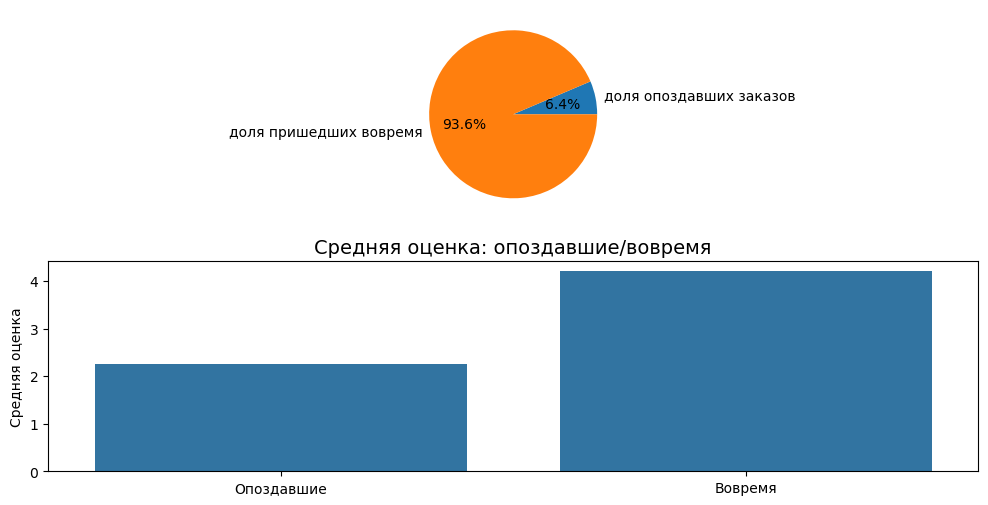

In [36]:
df['late'] = (df['order_delivered_customer_date'] - df['order_estimated_delivery_date']).dt.days
late = df[df['late'] > 0].shape[0]
normal =  df[df['late'] <= 0].shape[0]
ratio = round(late/normal * 100,2)

norm =   df[df['late'] <= 0]
late1 = df[df['late'] > 0] 

score_late = df[df['late'] > 0]['review_score'].mean()
score_normal = df[df['late'] <= 0]['review_score'].mean()

total = late + normal
a = [round(late/total*100, 2), round(normal/total*100, 2)]
b= ['доля опоздавших заказов', 'доля пришедших вовремя']
fig, axes = plt.subplots(2,1, figsize = (12,6))

axes[0].pie(a, labels = b, autopct='%1.1f%%')

categories = ['Опоздавшие', 'Вовремя']
means = [score_late, score_normal]
sns.barplot(x = categories, y = means)
plt.title('Средняя оценка: опоздавшие/вовремя', fontsize=14)
plt.ylabel('Средняя оценка')
print(means)

In [37]:
from scipy.stats import ttest_ind


late1 = df[df['late'] > 0]['review_score']
normal1 =  df[df['late'] <= 0]['review_score']
test = ttest_ind(normal1, late1)

# Вывод
**6,4% заказов были доставлены с опозданием. Средняя оценка опоздавших
заказов — 2,26 vs 4.21 у своевременных. T-test подтвердил статистическую
значимость разницы (p < 0.05) следовательно опоздание доставки достоверно
снижает оценку покупателя.**

## Ключевые выводы

1. Платформа показала рост 40x за год (2016→2017)
2. SP, RJ, MG формируют большую часть выручки
3. Топ категория по выручке — bed_bath_table
4. Скорость доставки — главный фактор оценки (p < 0.05)
5. 6.4% заказов доставляются с опозданием со средней оценкой 2.26